# Predicting Household Electricity Consumption in Sri Lanka

In this assignment I try to predict how much electricity a household uses in a month, using information about how the household lives (its appliances, rooms, members and type of house). I use the "Sri Lankan Residential Electricity Consumption" dataset from LIRNEasia on Kaggle. The algorithm I chose is LightGBM, a gradient boosting method that we did not cover in the lectures. I explain its predictions with SHAP and partial dependence plots, and at the end I build a small Streamlit app so that anyone can try the model.

##Setup

In this section I install the extra libraries (LightGBM and SHAP), download the data from Kaggle and set a few options. I fix a random seed so that my results can be repeated. I also added a switch called `USE_EXPENDITURE`. I keep it off because the household's reported monthly expenditure probably already includes the electricity bill, which would be like giving the model the answer.

In [ ]:
!pip install -q lightgbm shap

In [ ]:
!pip install -q kagglehub
import kagglehub, os, shutil

HANDLE = 'lirneasia/sri-lankan-residential-electricity-consumption'
wave1 = ['w1_ac_roster.csv', 'w1_appliances.csv', 'w1_demographics.csv',
         'w1_electricity_generation_water_heating_cooking.csv', 'w1_fan_roster.csv',
         'w1_household_information_and_history.csv', 'w1_light_roster.csv', 'w1_room_roster.csv']

roots = ['data/data/', 'data/', '']          # the Kaggle file tree has two nested "data" folders
wanted = {'monthly_consumption.csv': 'consumption_data/non_smart_meter/monthly_consumption.csv'}
wanted.update({n: f'survey_data/wave_1/{n}' for n in wave1})

os.makedirs('/content/data', exist_ok=True)
missing = []
for name, sub in wanted.items():
    for root in roots:
        try:
            p = kagglehub.dataset_download(HANDLE, path=root + sub)
            shutil.copy(p, '/content/data/' + name)
            print('OK:', root + sub)
            break
        except Exception as e:
            last = str(e)[:150]
    else:
        missing.append(name)
        print('FAILED:', name, '|', last)

print('\nStill missing:', missing)
print('Files in /content/data:', sorted(os.listdir('/content/data')))

100%|██████████| 2.08M/2.08M [00:01<00:00, 1.36MB/s]


OK: data/data/consumption_data/non_smart_meter/monthly_consumption.csv


100%|██████████| 252k/252k [00:00<00:00, 307kB/s]


OK: data/data/survey_data/wave_1/w1_ac_roster.csv


100%|██████████| 1.90M/1.90M [00:01<00:00, 1.27MB/s]


OK: data/data/survey_data/wave_1/w1_appliances.csv


... (8 outputs left out)

100%|██████████| 1.53M/1.53M [00:01<00:00, 1.06MB/s]


OK: data/data/survey_data/wave_1/w1_light_roster.csv


100%|██████████| 3.65M/3.65M [00:01<00:00, 2.08MB/s]

OK: data/data/survey_data/wave_1/w1_room_roster.csv

Still missing: []
Files in /content/data: ['monthly_consumption.csv', 'w1_ac_roster.csv', 'w1_appliances.csv', 'w1_demographics.csv', 'w1_electricity_generation_water_heating_cooking.csv', 'w1_fan_roster.csv', 'w1_household_information_and_history.csv', 'w1_light_roster.csv', 'w1_room_roster.csv']


In [ ]:
# Folder where the download cell above saved the CSV files
DATA_DIR = '/content/data'

# The "total monthly expenditure" survey answer probably includes the electricity bill itself,
# which would leak the answer. Keep False for the main model. Try True once and discuss it in the report.
USE_EXPENDITURE = False
RANDOM_STATE = 42

In [ ]:
import re, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)

def find(name):
    hits = glob.glob(f'{DATA_DIR}/**/{name}', recursive=True)
    assert hits, f'{name} not found under {DATA_DIR}. Check DATA_DIR.'
    return hits[0]

def load(name):
    df = pd.read_csv(find(name))
    df.columns = df.columns.str.strip()
    return df

## 1. Target variable

The goal is to predict a household's average monthly electricity use in kWh. The monthly consumption file has 25 monthly readings for each of the 4,063 households, but the values are stored as text and some of them are missing or invalid. So I first convert them to numbers and remove zero or invalid readings. Then I average the valid months of each household to get one target value per household, called `avg_monthly_kwh`. Very large values are capped so that a few extreme households do not dominate the training.

In [ ]:
cons = load('monthly_consumption.csv')
print(cons.shape)
print(cons.head())

cons['consumption'] = pd.to_numeric(cons['consumption'].astype(str).str.replace(',', '', regex=False), errors='coerce')
print('\nInvalid / missing consumption values:', cons['consumption'].isna().sum())
print(cons['consumption'].describe())
print('\nMonths per household:'); print(cons.groupby('household_ID').size().describe())

(101575, 3)
  household_ID       month consumption
0       ID0001  2022-10-31         116
1       ID0001  2022-11-30         120
2       ID0001  2022-12-31         129
3       ID0001  2023-01-31         102
4       ID0001  2023-02-28         115

Invalid / missing consumption values: 590
count    100985.000000
mean        122.144120
std         122.217922
min           0.000000
25%          60.000000
50%          96.000000
75%         148.000000
max        3025.000000
Name: consumption, dtype: float64

Months per household:
count    4063.0
mean       25.0
std         0.0
min        25.0
25%        25.0
50%        25.0
75%        25.0
max        25.0
dtype: float64


Households kept: 4023 | cap at 99.5th percentile = 746.9


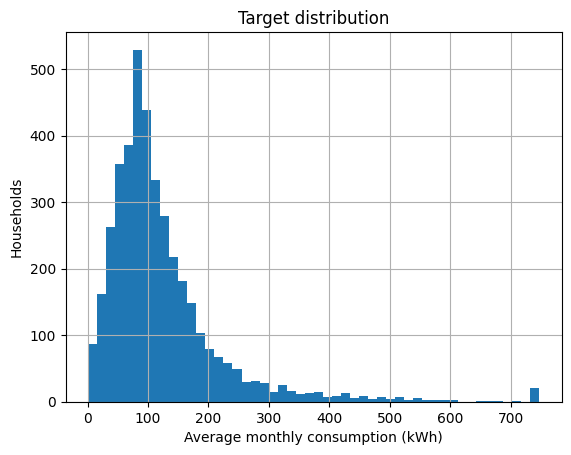

In [ ]:
valid = cons[cons['consumption'] > 0]                       # drop zero / negative / missing readings
target = valid.groupby('household_ID')['consumption'].agg(avg_monthly_kwh='mean', n_months='count')
target = target[target['n_months'] >= 6]                    # need at least 6 good months
cap = target['avg_monthly_kwh'].quantile(0.995)             # cap extreme outliers (IQR/percentile idea from Unit 2)
target['avg_monthly_kwh'] = target['avg_monthly_kwh'].clip(upper=cap)
print('Households kept:', len(target), '| cap at 99.5th percentile =', round(cap, 1))
target['avg_monthly_kwh'].hist(bins=50); plt.xlabel('Average monthly consumption (kWh)'); plt.ylabel('Households'); plt.title('Target distribution'); plt.show()

## 2. Features from the Wave 1 survey

The features come from the Wave 1 survey, which describes the living conditions of each household. Some of the tables already have one row per household. The AC, fan, light, room, appliance and household member tables have one row per item or person, so I first summarise them into one row per household (for example the number of ACs, total hours the fans were used, total bulb wattage, number of appliances and the average age of the members). After that I join everything with the target using `household_ID`.

In [ ]:
# --- tables that already have one row per household ---
hh = load('w1_household_information_and_history.csv')
if not USE_EXPENDITURE:
    hh = hh.drop(columns=['total_monthly_expenditure_of_last_month'], errors='ignore')
hh = hh.drop_duplicates('household_ID').set_index('household_ID')

gen_cols = ['household_ID', 'have_backup_generator', 'generate_electicity_using_solar_energy',
            'solar_system_ongrid_or_offgird', 'no_of_units_generated_by_solar_system',
            'water_heating_method_for_bathing', 'electricity_from_national_grid_used_for_cooking',
            'gas_used_for_cooking', 'boil_water_before_drinking', 'source_of_energy_for_boiling_drinking_water']
gen = load('w1_electricity_generation_water_heating_cooking.csv')
gen = gen[[c for c in gen_cols if c in gen.columns]].drop_duplicates('household_ID').set_index('household_ID')
gen['no_of_units_generated_by_solar_system'] = gen['no_of_units_generated_by_solar_system'].fillna(0)  # no solar -> 0

# --- roster tables: summarise to one row per household ---
ac = load('w1_ac_roster.csv')
ac['hours'] = ac['no_of_hours_ac_was_on_during_daytime_last_week'].fillna(0) + ac['no_of_hours_ac_was_on_during_night_last_week'].fillna(0)
ac_f = ac.groupby('household_ID').agg(n_ac=('ac_ID', 'count'), ac_watts_total=('wattage_of_the_ac', 'sum'),
                                      ac_btu_total=('btu_of_the_ac', 'sum'), ac_hours_week=('hours', 'sum'))

fan = load('w1_fan_roster.csv')
fan['hours'] = fan['no_of_hours_fan_was_on_during_daytime_last_week'].fillna(0) + fan['no_of_hours_fan_was_on_during_night_last_week'].fillna(0)
fan_f = fan.groupby('household_ID').agg(n_fans=('fan_ID', 'count'), fan_hours_week=('hours', 'sum'))

light = load('w1_light_roster.csv')
light['hours'] = light['no_of_hours_bulb_was_on_during_daytime_last_week'].fillna(0) + light['no_of_hours_bulb_was_on_during_night_last_week'].fillna(0)
light['watt_hours'] = light['wattage_of_the_bulb'] * light['hours']
light_f = light.groupby('household_ID').agg(n_lights=('light_ID', 'count'), light_watts_total=('wattage_of_the_bulb', 'sum'),
                                            light_hours_week=('hours', 'sum'), light_watt_hours_week=('watt_hours', 'sum'))

room = load('w1_room_roster.csv')
room_f = room.groupby('household_ID').agg(n_rooms=('room_ID', 'count'), windows_total=('no_of_windows', 'sum'),
                                          external_doors_total=('no_of_doors_opened_to_external_environment', 'sum'))

app = load('w1_appliances.csv')
app_f = app.groupby('household_ID').agg(n_appliances=('appliance_ID', 'count'), appliance_hours_week=('no_of_hours_used_during_last_week', 'sum'))
top_types = app['appliance_type'].value_counts().head(15).index          # count of the 15 most common appliance types
ap_counts = pd.crosstab(app['household_ID'], app['appliance_type'])[top_types]
ap_counts.columns = ['app_' + str(c) for c in ap_counts.columns]

demo = load('w1_demographics.csv')
demo['is_child'] = demo['age'] < 15
demo['is_senior'] = demo['age'] >= 60
demo_f = demo.groupby('household_ID').agg(n_members_listed=('member_ID', 'count'), mean_age=('age', 'mean'),
                                          share_children=('is_child', 'mean'), share_seniors=('is_senior', 'mean'),
                                          mean_hours_home=('no_of_hours_stayed_at_home_during_last_week', 'mean'))
print('Appliance types used as features:', list(top_types))

Appliance types used as features: ['Mobile phone - Smart phones', 'Refrigerator', 'Electric Iron including electric steam iron', 'TV', 'Rice cooker', 'Electric Blender', 'Washing Machine', 'Laptops', 'Mobile phone - Basic phones', 'Dialog TV / Peo TV / Satellite TV box', 'Electric Kettle', 'Toaster / Sandwich toaster', 'Radio', 'TV antenna', 'Routers']


In [ ]:
data = target[['avg_monthly_kwh']].join([hh, gen, ac_f, fan_f, light_f, room_f, app_f, ap_counts, demo_f], how='left')

# households with no AC / fan / light / appliance rows really have zero of them
zero_fill = list(ac_f.columns) + list(fan_f.columns) + list(light_f.columns) + list(app_f.columns) + list(ap_counts.columns)
data[zero_fill] = data[zero_fill].fillna(0)

print('Final table:', data.shape)
data.head()

Final table: (4023, 69)


,avg_monthly_kwh,no_of_electricity_meters,electricity_provider_csc_area,own_the_house_or_living_on_rent,occupy_renters_boarders,awareness_of_electricity_consumption_of_renters,built_year_of_the_house,type_of_house,floor_which_house_located,no_of_storeys,floor_area,no_of_household_members,charging_method_of_renters_for_electricity,charged_method_for_rent_for_electricity,is_there_business_carried_out_in_the_household,type_of_business,whom_or_how_the_house_was_designed,availability_of_certificate_of_compliance,main_material_used_for_walls_of_the_house,main_material_used_for_roof_of_the_house,any_constructions_or_renovations_in_the_household,highest_level_of_education_of_the_chief_wage_earner,occupation_of_the_chief_wage_earner,socio_economic_class,type_of_electricity_meter,...,n_rooms,windows_total,external_doors_total,n_appliances,appliance_hours_week,app_Mobile phone - Smart phones,app_Refrigerator,app_Electric Iron including electric steam iron,app_TV,app_Rice cooker,app_Electric Blender,app_Washing Machine,app_Laptops,app_Mobile phone - Basic phones,app_Dialog TV / Peo TV / Satellite TV box,app_Electric Kettle,app_Toaster / Sandwich toaster,app_Radio,app_TV antenna,app_Routers,n_members_listed,mean_age,share_children,share_seniors,mean_hours_home
household_ID,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
ID0001,95.166667,1,GALLE,"Yes, I or a household member owns it.",I don't occupy any of the above.,NaN,2000-2009,Single House - Double Floor,NaN,NaN,1500.0,4,NaN,NaN,No,NaN,The house is designed by a certified architect.,No,Brick,Asbestos,No,O/L or A/L pending / Passed,Skilled Worker,SEC C,Non smart meter,...,10,7.0,7.0,8.0,98.00,2.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,4,49.75,0.00,0.500000,139.0
ID0002,47.360000,1,GALLE,"Yes, I or a household member owns it.",I don't occupy any of the above.,NaN,Before 1980,Single House - Single Floor,NaN,NaN,440.0,3,NaN,NaN,No,NaN,This is a house provided by the government.,Yes,Brick,Asbestos,No,Diploma with O/L or A/L (Non graduate),Unskilled Worker,SEC D,Non smart meter,...,10,21.0,14.0,4.0,168.00,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,3,70.00,0.00,0.666667,112.0
ID0003,188.520000,1,GALLE,"Yes, I or a household member owns it.",I don't occupy any of the above.,NaN,1980-1989,Single House - Single Floor,NaN,NaN,2500.0,4,NaN,NaN,No,NaN,The house is designed by a certified architect.,No,Brick,Tile,No,Graduate / Post-Grads / Degree level professio...,Middle and Senior executive,SEC A,Smart meter,...,10,9.0,11.0,19.0,226.51,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,1.0,4,42.50,0.25,0.250000,117.0
ID0004,236.240000,1,BORALASGAMUWA,"Yes, I or a household member owns it.",I don't occupy any of the above.,NaN,2010-2019,Single House - Double Floor,NaN,NaN,2600.0,4,NaN,NaN,No,NaN,The house is designed by a certified architect.,No,Cement Block,Concrete,No,Other professional certificates with O/L or A/...,1-9 Employed,SEC A,Smart meter,...,12,14.0,12.0,16.0,218.00,2.0,1.0,1.0,1.0,1.0,1.0,1.0,0.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,4,35.50,0.25,0.250000,114.0
ID0005,94.040000,1,KOLONNAWA,"Yes, I or a household member owns it.",I don't occupy any of the above.,NaN,2010-2019,Flat,10.0,1.0,480.0,2,NaN,NaN,No,NaN,The house is designed by a certified architect.,Yes,I am not aware of that,Concrete,No,Schooling up to Grade 6 - 9,Skilled Worker,SEC D,Smart meter,...,5,6.0,2.0,11.0,391.50,2.0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,2,67.50,0.00,0.500000,126.0


## 3. Cleaning and encoding

Before training, I clean the combined table. Columns that are mostly empty or have only one value are removed. Text columns are turned into categories, and rare categories (less than 1% of households) are grouped into "Other". Missing numbers are left as they are for LightGBM, which can handle them, and for the baseline models I fill them with the median of the training data.

In [ ]:
y = data.pop('avg_monthly_kwh')

data = data.loc[:, data.isna().mean() <= 0.60]
data.columns = [re.sub(r'[^0-9a-zA-Z_]+', '_', str(c)).strip('_') for c in data.columns]   # LightGBM dislikes special characters
data = data.loc[:, data.nunique(dropna=True) > 1]

cat_cols = data.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
for c in cat_cols:
    s = data[c].astype(str).str.strip().replace({'nan': 'Missing', '': 'Missing'})
    rare = s.value_counts(normalize=True)
    rare = rare[rare < 0.01].index
    data[c] = s.where(~s.isin(rare), 'Other').astype(object)
num_cols = [c for c in data.columns if c not in cat_cols]

print(len(num_cols), 'numeric features,', len(cat_cols), 'categorical features')
print('Categorical:', cat_cols)

39 numeric features, 22 categorical features
Categorical: ['electricity_provider_csc_area', 'own_the_house_or_living_on_rent', 'occupy_renters_boarders', 'built_year_of_the_house', 'type_of_house', 'is_there_business_carried_out_in_the_household', 'whom_or_how_the_house_was_designed', 'availability_of_certificate_of_compliance', 'main_material_used_for_walls_of_the_house', 'main_material_used_for_roof_of_the_house', 'any_constructions_or_renovations_in_the_household', 'highest_level_of_education_of_the_chief_wage_earner', 'occupation_of_the_chief_wage_earner', 'socio_economic_class', 'type_of_electricity_meter', 'have_backup_generator', 'generate_electicity_using_solar_energy', 'water_heating_method_for_bathing', 'electricity_from_national_grid_used_for_cooking', 'gas_used_for_cooking', 'boil_water_before_drinking', 'source_of_energy_for_boiling_drinking_water']


## 4. Train / validation / test split

I split the households into 70% training, 15% validation and 15% test sets. The training set is used to learn and tune the models, the validation set is used to compare them, and the test set is kept for the final check, so the final scores are on households that the model has never seen. Each household is only one row, so no household appears in more than one set.

In [ ]:
from sklearn.model_selection import train_test_split
idx_train, idx_tmp = train_test_split(data.index.to_numpy(), test_size=0.30, random_state=RANDOM_STATE)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.50, random_state=RANDOM_STATE)
print(len(idx_train), len(idx_val), len(idx_test))

# version for LightGBM (native categories, NaN allowed)
X_lgb = data.copy()
for c in cat_cols:
    X_lgb[c] = pd.Categorical(X_lgb[c])

# version for linear model / random forest (one-hot, no NaN)
X_lin = pd.get_dummies(data, columns=cat_cols, drop_first=True, dtype=float)
X_lin = X_lin.fillna(X_lin.loc[idx_train].median())

2816 603 604


## 5. Baseline models

Before using the new algorithm I need something to compare it with. I train three simple baselines: predicting the average consumption for every household, Ridge regression (a regularised linear regression from Units 2 and 3) and a Random Forest (Unit 6). If the new model cannot do better than these, then it is not worth using.

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

results = []
def evaluate(name, model, X):
    for split, idx in [('validation', idx_val), ('test', idx_test)]:
        p = model.predict(X.loc[idx])
        results.append({'model': name, 'split': split,
                        'RMSE': np.sqrt(mean_squared_error(y.loc[idx], p)),
                        'MAE': mean_absolute_error(y.loc[idx], p),
                        'R2': r2_score(y.loc[idx], p)})

dummy = DummyRegressor(strategy='mean').fit(X_lin.loc[idx_train], y.loc[idx_train])
ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))).fit(X_lin.loc[idx_train], y.loc[idx_train])
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=RANDOM_STATE, n_jobs=-1).fit(X_lin.loc[idx_train], y.loc[idx_train])

evaluate('Predict the mean', dummy, X_lin)
evaluate('Ridge (linear regression)', ridge, X_lin)
evaluate('Random Forest', rf, X_lin)
pd.DataFrame(results).round(3)

,model,split,RMSE,MAE,R2
0,Predict the mean,validation,91.871,62.743,-0.001
1,Predict the mean,test,96.686,62.039,-0.001
2,Ridge (linear regression),validation,68.522,42.969,0.443
3,Ridge (linear regression),test,74.968,44.408,0.398
4,Random Forest,validation,68.408,41.636,0.445
5,Random Forest,test,71.572,43.152,0.452


## 6. The new algorithm: LightGBM

The new algorithm I chose is LightGBM, which is a gradient boosting method. A Random Forest builds many trees independently and averages them, but in boosting the trees are built one after another and each new tree tries to correct the mistakes of the previous ones. I chose LightGBM because it is fast, works well on tabular survey data like this, and can use categories and missing values directly. I tune its hyperparameters using 5-fold cross-validation on the training set only, and then compare it with the baselines using RMSE, MAE and R².

In [ ]:
import lightgbm as lgb
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators': [200, 400, 600],
    'learning_rate': [0.02, 0.05, 0.1],
    'num_leaves': [8, 16, 31],
    'max_depth': [-1, 4, 6],
    'min_child_samples': [10, 20, 40],
    'subsample': [0.7, 0.85, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'reg_lambda': [0, 1, 5],
}
base = lgb.LGBMRegressor(random_state=RANDOM_STATE, subsample_freq=1, verbose=-1, n_jobs=1)
search = RandomizedSearchCV(base, param_dist, n_iter=25, cv=5, scoring='neg_root_mean_squared_error',
                            random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_lgb.loc[idx_train], y.loc[idx_train])
best = search.best_estimator_
print('Best hyperparameters:', search.best_params_)
print('Best CV RMSE:', round(-search.best_score_, 2))

evaluate('LightGBM (tuned)', best, X_lgb)
res = pd.DataFrame(results).round(3)
res

Best hyperparameters: {'subsample': 0.85, 'reg_lambda': 5, 'num_leaves': 8, 'n_estimators': 600, 'min_child_samples': 40, 'max_depth': 4, 'learning_rate': 0.02, 'colsample_bytree': 0.6}
Best CV RMSE: 71.09


,model,split,RMSE,MAE,R2
0,Predict the mean,validation,91.871,62.743,-0.001
1,Predict the mean,test,96.686,62.039,-0.001
2,Ridge (linear regression),validation,68.522,42.969,0.443
3,Ridge (linear regression),test,74.968,44.408,0.398
4,Random Forest,validation,68.408,41.636,0.445
5,Random Forest,test,71.572,43.152,0.452
6,LightGBM (tuned),validation,67.745,41.142,0.456
7,LightGBM (tuned),test,69.800,41.258,0.478


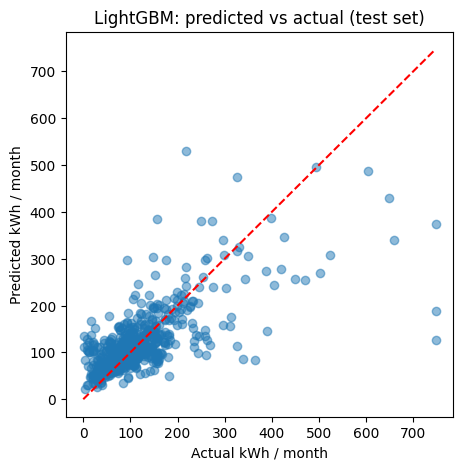

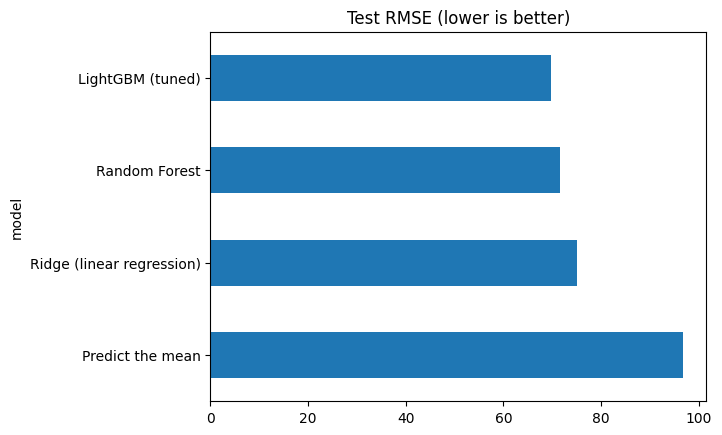

In [ ]:
# Predicted vs actual on the TEST set
p = best.predict(X_lgb.loc[idx_test])
plt.figure(figsize=(5, 5))
plt.scatter(y.loc[idx_test], p, alpha=0.5)
lim = [0, max(y.loc[idx_test].max(), p.max())]
plt.plot(lim, lim, 'r--'); plt.xlabel('Actual kWh / month'); plt.ylabel('Predicted kWh / month')
plt.title('LightGBM: predicted vs actual (test set)'); plt.show()

# Model comparison bar chart (test RMSE)
res[res.split == 'test'].set_index('model')['RMSE'].plot.barh(title='Test RMSE (lower is better)'); plt.show()

## 7. Explainability (SHAP and partial dependence)

I use SHAP to see which features push the predicted consumption up or down, both overall and for one single household. I also use partial dependence plots to see how the prediction changes when one important feature changes. After that I check whether the model agrees with common sense, for example that more air conditioner use should mean higher electricity consumption.

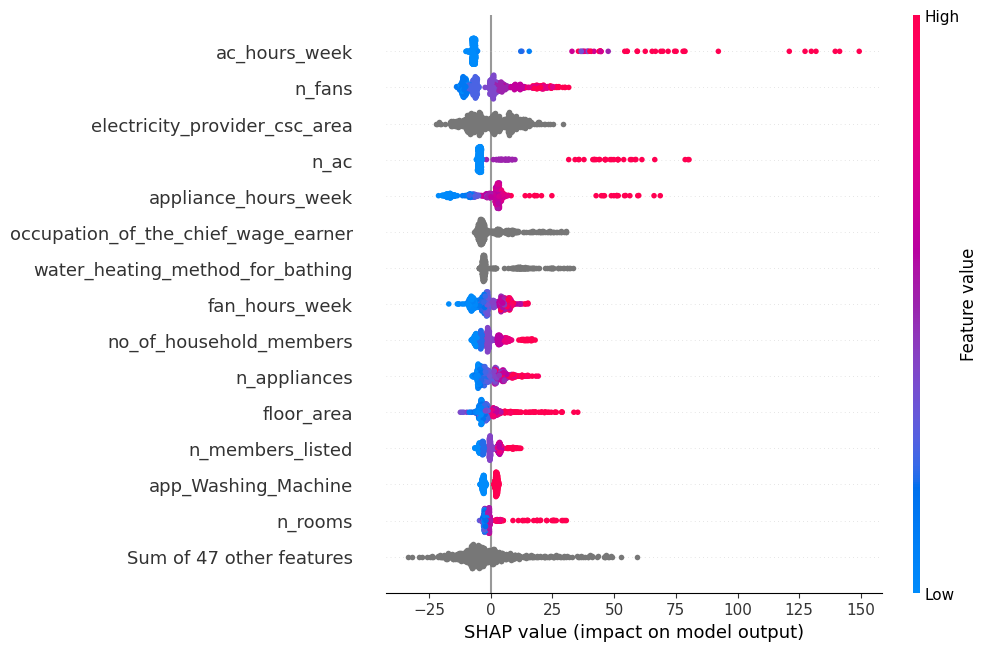

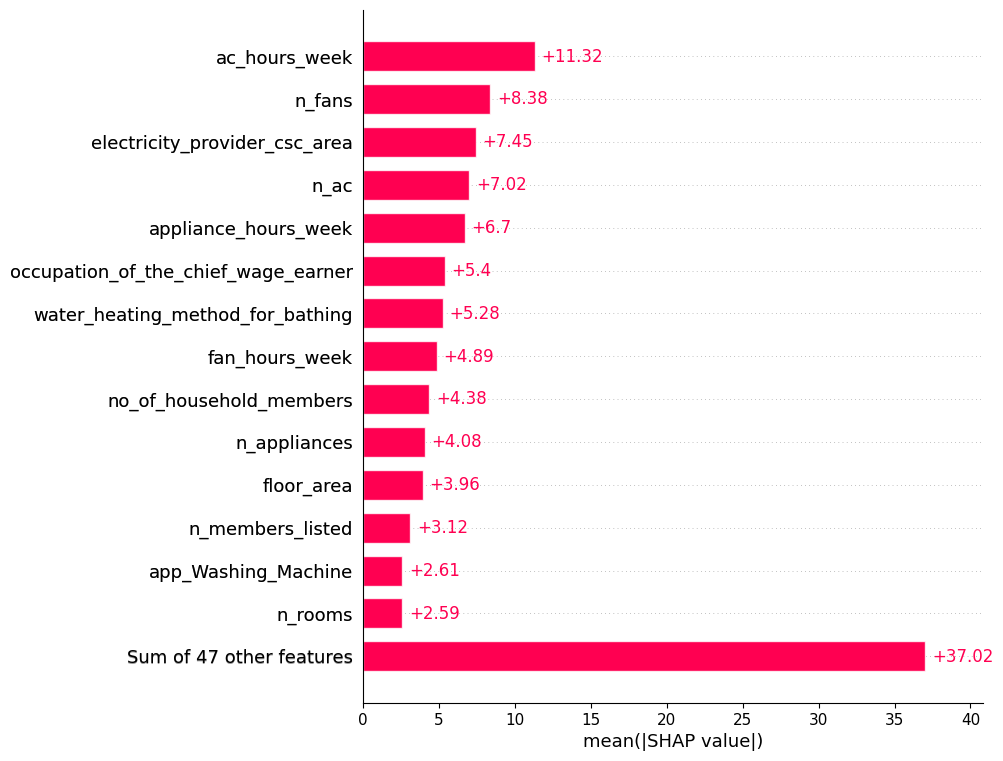

In [ ]:
import shap
X_test = X_lgb.loc[idx_test]
explainer = shap.TreeExplainer(best)
sv = explainer(X_test)

shap.plots.beeswarm(sv, max_display=15)     # global: which features matter and in which direction
shap.plots.bar(sv, max_display=15)          # global: mean |SHAP|

Actual: 245.3 | Predicted: 134.4


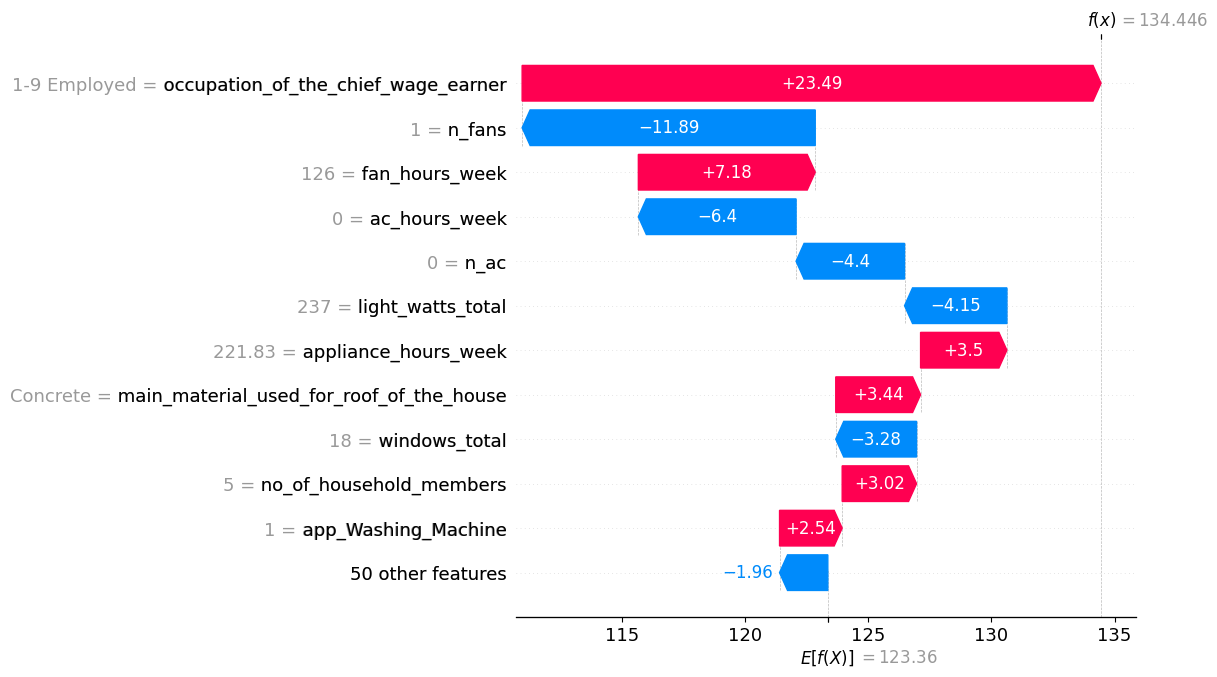

In [ ]:
# Local explanation: why did the model predict this value for ONE household?
i = 0
print('Actual:', round(y.loc[X_test.index[i]], 1), '| Predicted:', round(float(best.predict(X_test.iloc[[i]])[0]), 1))
shap.plots.waterfall(sv[i], max_display=12)

ac_hours_week                                     11.32
n_fans                                             8.38
electricity_provider_csc_area                      7.45
n_ac                                               7.02
appliance_hours_week                               6.70
occupation_of_the_chief_wage_earner                5.40
water_heating_method_for_bathing                   5.28
fan_hours_week                                     4.89
no_of_household_members                            4.38
n_appliances                                       4.08
floor_area                                         3.96
n_members_listed                                   3.12
app_Washing_Machine                                2.61
n_rooms                                            2.59
is_there_business_carried_out_in_the_household     2.42
dtype: float64


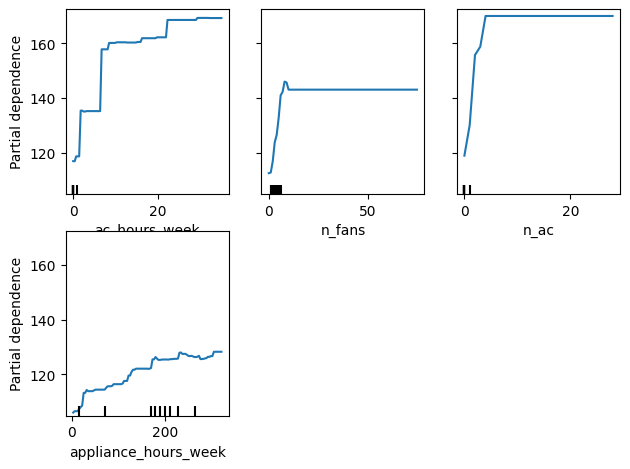

In [ ]:
imp = pd.Series(np.abs(sv.values).mean(axis=0), index=X_test.columns).sort_values(ascending=False)
print(imp.head(15).round(2))

# Partial dependence of the top numeric features
from sklearn.inspection import PartialDependenceDisplay
ranked_num = [c for c in imp.index if c in num_cols]
top_num = ranked_num[:4]
PartialDependenceDisplay.from_estimator(best, X_lgb.loc[idx_train], top_num, kind='average')
plt.tight_layout(); plt.show()

## 8. Saving the model for the front-end

Here I save the trained model, together with the information the app needs to use it, into `model.joblib`. I also create a `requirements.txt` file and the `app.py` file for the app.

In [ ]:
import joblib
ui_feats = ranked_num[:6]                      # the sliders shown in the app
Xtr = X_lgb.loc[idx_train]
bundle = {
    'model': best,
    'columns': list(X_lgb.columns),
    'cat_cols': cat_cols,
    'categories': {c: [str(v) for v in X_lgb[c].cat.categories] for c in cat_cols},
    'defaults': {c: (str(Xtr[c].mode()[0]) if c in cat_cols else float(Xtr[c].median())) for c in X_lgb.columns},
    'ui_features': [{'name': c,
                     'min': float(Xtr[c].quantile(0.01)),
                     'max': float(max(Xtr[c].quantile(0.99), Xtr[c].quantile(0.01) + 1)),
                     'default': float(Xtr[c].median()),
                     'step': 1.0 if (Xtr[c].dropna() % 1 == 0).all() else 0.1} for c in ui_feats],
}
joblib.dump(bundle, 'model.joblib')

import lightgbm, sklearn
reqs = (f"streamlit\nlightgbm=={lightgbm.__version__}\nscikit-learn=={sklearn.__version__}\n"
        f"shap=={shap.__version__}\npandas=={pd.__version__}\nnumpy\njoblib\nmatplotlib\n")
open('requirements.txt', 'w').write(reqs)
print(reqs)

streamlit
lightgbm==4.6.0
scikit-learn==1.6.1
shap==0.54.1
pandas==2.2.3
numpy
joblib
matplotlib



In [ ]:
%%writefile app.py
import joblib
import pandas as pd
import streamlit as st
import shap
import matplotlib.pyplot as plt

st.set_page_config(page_title='Household electricity predictor')

@st.cache_resource
def load_bundle():
    return joblib.load('model.joblib')

b = load_bundle()
st.title('Household electricity consumption predictor')
st.write('Enter some household details. The model predicts the average monthly consumption (kWh) '
         'and shows which factors pushed the prediction up or down. All other details are set to typical values.')

inputs = {}
for f in b['ui_features']:
    inputs[f['name']] = st.slider(f['name'].replace('_', ' '), float(f['min']), float(f['max']),
                                  float(min(max(f['default'], f['min']), f['max'])), step=float(f['step']))

row = pd.DataFrame([b['defaults']])[b['columns']]
for k, v in inputs.items():
    row[k] = v
for c in b['cat_cols']:
    row[c] = pd.Categorical(row[c], categories=b['categories'][c])

pred = float(b['model'].predict(row)[0])
st.metric('Predicted consumption (kWh per month)', f'{pred:.0f}')

st.subheader('Why this prediction?')
sv = shap.TreeExplainer(b['model'])(row)
shap.plots.waterfall(sv[0], max_display=10, show=False)
st.pyplot(plt.gcf())
plt.close('all')

Writing app.py
